# 02 — Preparación y validación de datos

En este cuaderno ejecutamos la preparación de src/data: integramos las imágenes de calidad conocida y las anotaciones aprobadas, estimamos tamaño relativo, hacemos particiones reproducibles sin compartir grupos, procesamos imágenes a 128 × 128 y generamos vectores de 108 características. Los recortes Mixed se generan y quedan fuera del entrenamiento hasta que sus etiquetas revisadas estén en `data/annotations/mixed_candidates_annotations.csv`.

La disponibilidad de Regular, fotos propias y anotaciones se valida en cada ejecución. Si falta una clase, se muestra con soporte cero y el resultado posterior será piloto, no evaluación final de tres clases. El reinicio conserva `data/annotations/` y los marcadores .gitkeep versionados.

In [7]:
%pip install opencv-python==4.12.0.88

Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_python-4.12.0.88-cp37-abi3-win_amd64.whl.metadata (19 kB)
Using cached opencv_python-4.12.0.88-cp37-abi3-win_amd64.whl (39.0 MB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   -------- ------------------------------- 2.6/12.6 MB 9.3 MB/s eta 0:00:02
   -------------------------- ------------- 8.4/12.6 MB 19.2 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 19.7 MB/s  0:00:00

   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ---------------------------------------- 0/2 [numpy]
   ----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.25.0 requires numpy>=2.3.5, but you have numpy 2.2.6 which is incompatible.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [5]:
import sys
print(sys.executable)

c:\ProgramData\anaconda3\python.exe


In [8]:
from contextlib import redirect_stderr, redirect_stdout
from io import StringIO
from pathlib import Path
import json
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.dataset import FINAL_QUALITY_CLASSES, scan_labeled_dataset
from src.data.feature_extraction import FEATURE_DIM
from src.data.prepare_data import PROCESSED_DIR, RAW_KAGGLE, run_eda_pipeline
from src.data.load_data import load_ml_arrays

PROCESSED_DIR = PROCESSED_DIR.resolve()
assert PROCESSED_DIR == (ROOT / "data" / "processed").resolve()
print(f"Dataset de entrada: {RAW_KAGGLE}")
print(f"Salidas procesadas: {PROCESSED_DIR}")
print(f"Marcador de anotaciones conservado: {(PROCESSED_DIR / 'annotations.csv').exists()}")

Dataset de entrada: C:\Apo3\Proyecto-APO\apo3-mangoMelocoton\data\raw\kaggle
Salidas procesadas: C:\Apo3\Proyecto-APO\apo3-mangoMelocoton\data\processed
Marcador de anotaciones conservado: True


In [9]:
# Reiniciamos solo las salidas derivadas; conservamos anotaciones y archivos .gitkeep.
log_buffer = StringIO()
start = time.perf_counter()
with redirect_stdout(log_buffer), redirect_stderr(log_buffer):
    run_summary = run_eda_pipeline(reset_processed=True)
elapsed_minutes = (time.perf_counter() - start) / 60
log_lines = [line.strip() for line in log_buffer.getvalue().replace("\r", "\n").splitlines() if line.strip()]
print(f"Resumen del pipeline: {run_summary}")
print(f"Duración: {elapsed_minutes:.1f} min")
print("Últimas líneas del proceso:")
print("\n".join(log_lines[-12:]))

Resumen del pipeline: {'manifest_size': 18873, 'train_size': 13211, 'val_size': 2831, 'test_size': 2831, 'split_summary': {'seed': 42, 'target_proportions': {'train': 0.7, 'validation': 0.15, 'test': 0.15}, 'strategy': 'stratified', 'splits': {'train': {'samples': 13211, 'groups': 13211, 'class_counts': {'Good': 8459, 'Regular': 0, 'Bad': 4752}}, 'validation': {'samples': 2831, 'groups': 2831, 'class_counts': {'Good': 1813, 'Regular': 0, 'Bad': 1018}}, 'test': {'samples': 2831, 'groups': 2831, 'class_counts': {'Good': 1813, 'Regular': 0, 'Bad': 1018}}}, 'shared_groups': {'train_validation': 0, 'train_test': 0, 'validation_test': 0}}}
Duración: 11.5 min
Últimas líneas del proceso:
test/Bad: 100%|##########| 1018/1018 [00:05<00:00, 198.37it/s]
EDA/preparation completed.


In [10]:
manifest = pd.read_csv(PROCESSED_DIR / "final_manifest.csv")
splits = {name: pd.read_csv(PROCESSED_DIR / f"{name}.csv") for name in ["train", "val", "test"]}
with (PROCESSED_DIR / "labelinfo.json").open(encoding="utf-8") as file:
    label_info = json.load(file)
with (PROCESSED_DIR / "classweights.json").open(encoding="utf-8") as file:
    class_weights = json.load(file)
with (PROCESSED_DIR / "split_summary.json").open(encoding="utf-8") as file:
    split_summary = json.load(file)

assert label_info["class_names"] == FINAL_QUALITY_CLASSES
assert set(manifest["quality"].unique()).issubset(set(FINAL_QUALITY_CLASSES))
assert len(manifest) == sum(len(split) for split in splits.values())
assert all(split["processed_path"].map(lambda path: Path(path).is_file()).all() for split in splits.values())

split_counts = pd.DataFrame({name: split["quality"].value_counts() for name, split in splits.items()}).fillna(0).astype(int)
split_counts = split_counts.reindex(FINAL_QUALITY_CLASSES, fill_value=0)
split_counts.loc["Total"] = split_counts.sum(axis=0)
display(split_counts)
display(pd.DataFrame(split_summary["splits"]).T)
print(f"Manifest supervisado: {len(manifest):,} imágenes")
print(f"Mapa de clases: {label_info['label_map']}")
print(f"Pesos de las clases con datos: {class_weights}")

,train,val,test
quality,,,
Good,8459,1813,1813
Regular,0,0,0
Bad,4752,1018,1018
Total,13211,2831,2831


,samples,groups,class_counts
train,13211,13211,"{'Good': 8459, 'Regular': 0, 'Bad': 4752}"
validation,2831,2831,"{'Good': 1813, 'Regular': 0, 'Bad': 1018}"
test,2831,2831,"{'Good': 1813, 'Regular': 0, 'Bad': 1018}"


Manifest supervisado: 18,873 imágenes
Mapa de clases: {'Good': 0, 'Regular': 1, 'Bad': 2}
Pesos de las clases con datos: {'0': 0.7808842652795839, '2': 1.3900462962962963}


In [11]:
groups = {name: set(split["group_id"].astype(str)) for name, split in splits.items()}
for left, right in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = groups[left] & groups[right]
    print(f"Grupos compartidos {left}/{right}: {len(overlap)}")
    assert not overlap, f"Fuga de grupos entre {left} y {right}"

arrays = load_ml_arrays(PROCESSED_DIR)
array_summary = []
for name in ["train", "val", "test"]:
    X, y = arrays[f"X{name}"], arrays[f"y{name}"]
    assert X.ndim == 2 and X.shape[1] == FEATURE_DIM
    assert y.ndim == 1 and len(y) == len(X)
    assert np.isfinite(X).all(), f"Hay valores no finitos en X{name}"
    expected_counts = split_counts[name].reindex(FINAL_QUALITY_CLASSES, fill_value=0).to_numpy()
    observed_counts = np.bincount(y, minlength=len(FINAL_QUALITY_CLASSES))
    assert np.array_equal(observed_counts, expected_counts), f"Desalineación de etiquetas en {name}"
    array_summary.append({"split": name, "X_shape": X.shape, "y_shape": y.shape, "counts_by_label_index": observed_counts.tolist()})
display(pd.DataFrame(array_summary))
display(manifest["size_label"].fillna("unknown").value_counts().rename("images").to_frame())

Grupos compartidos train/val: 0
Grupos compartidos train/test: 0
Grupos compartidos val/test: 0


,split,X_shape,y_shape,counts_by_label_index
0,train,"(13211, 108)","(13211,)","[8459, 0, 4752]"
1,val,"(2831, 108)","(2831,)","[1813, 0, 1018]"
2,test,"(2831, 108)","(2831,)","[1813, 0, 1018]"


,images
size_label,
large,15583
medium,1958
unknown,1188
small,144


## Escenas Mixed: recortes candidatos sin calidad asignada

Las escenas Mixed se segmentan automáticamente y cada recorte conserva `source_image_id` y `group_id`. El pipeline crea/actualiza una plantilla en `data/annotations/mixed_candidates_annotations.csv`; solo los recortes con Good, Regular o Bad aprobados se incorporan al manifiesto y a las particiones. Los pendientes nunca se entrenan.

In [12]:
_, mixed_public = scan_labeled_dataset(RAW_KAGGLE, "kaggle")
MIXED_OUTPUT = PROCESSED_DIR / "images" / "mixed_candidates"
manifest_path = MIXED_OUTPUT / "manifest.csv"
if manifest_path.is_file() and manifest_path.stat().st_size:
    mixed_manifest = pd.read_csv(manifest_path)
else:
    from src.data.dataset import empty_manifest
    mixed_manifest = empty_manifest()

if len(mixed_public) != 1_074:
    print(f"La referencia auditada es 1,074 escenas Mixed; el conteo observado es {len(mixed_public):,}. Verifique la versión de la descarga.")
if not mixed_manifest.empty:
    assert mixed_manifest["quality"].fillna("").eq("").all()
    assert mixed_manifest["group_id"].notna().all()

crops_per_source = mixed_manifest.groupby("source_image_id").size()
print(f"Escenas Mixed de entrada: {len(mixed_public):,}")
print(f"Recortes candidatos: {len(mixed_manifest):,}")
print(f"Escenas con recorte: {crops_per_source.size:,}")
print(f"Manifiesto: {manifest_path}")
display(crops_per_source.describe().to_frame("crops_per_scene"))

Escenas Mixed de entrada: 1,074
Recortes candidatos: 1,318
Escenas con recorte: 1,074
Manifiesto: C:\Apo3\Proyecto-APO\apo3-mangoMelocoton\data\processed\images\mixed_candidates\manifest.csv


,crops_per_scene
count,1074.000000
mean,1.227188
std,0.667838
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,6.000000


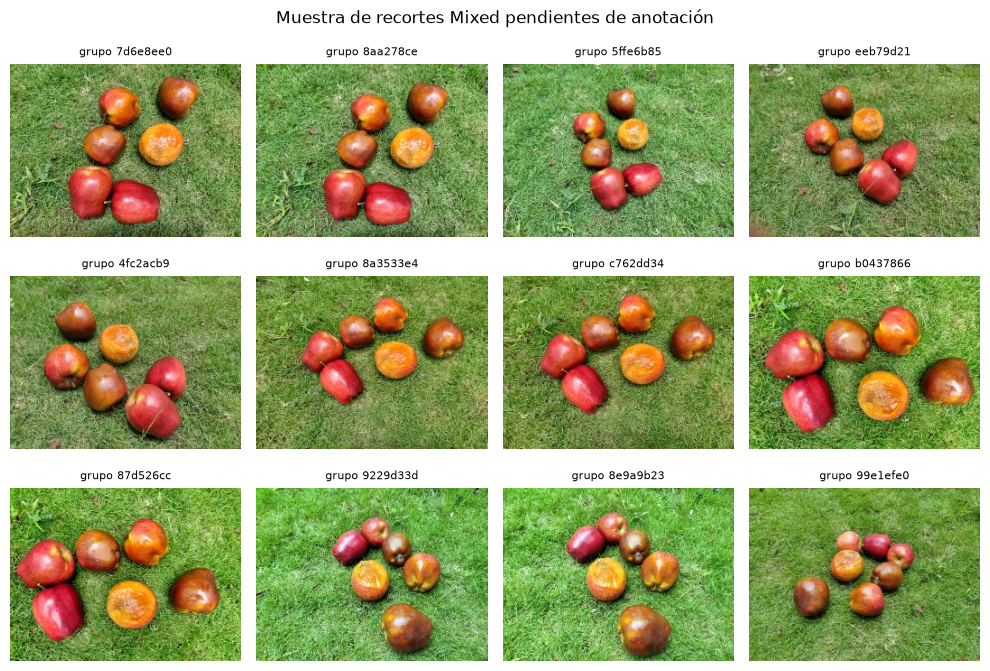

In [13]:
sample_crops = mixed_manifest.head(12)
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for ax, (_, row) in zip(axes.flat, sample_crops.iterrows()):
    ax.axis("off")
    image = cv2.imread(row["path"])
    if image is not None:
        h, w = image.shape[:2]
        scale = min(1.0, 320 / max(h, w))
        if scale < 1.0:
            image = cv2.resize(image, (round(w * scale), round(h * scale)))
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(f"grupo {row['group_id'][-8:]}", fontsize=8)
for ax in axes.flat[len(sample_crops):]:
    ax.axis("off")
fig.suptitle("Muestra de recortes Mixed pendientes de anotación")
fig.tight_layout()
plt.show()

## Resultado de la preparación

El manifiesto y los arrays incluyen solo registros con calidad revisada. Las clases ausentes se muestran con soporte cero y no se consideran evaluadas; si Regular aún no aparece en todas las particiones, los cuadernos 03/04 identifican el resultado como piloto Good/Bad. El tamaño generado es relativo a píxeles, no una medida física; se necesita calibración con referencias para reportar error en mm.